**mount drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**1. Import libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**2. load dataset**

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/ai4i2020.csv')

In [ ]:
df

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


**3. Dataset understanding**

**3.1 Shape**

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10000
Number of columns: 14


**3.2 Head**

In [ ]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


**3.3 Data Types**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

**3.4 Missing Values**

In [ ]:
missing_values = df.isnull().sum()
print(missing_values)
print("\nTotal missing values:", missing_values.sum())

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Total missing values: 0


**3.5 Duplicate Values**

In [ ]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


**4. Exploratory Data Analysis**

**4.1 Target Distribution**

In [ ]:
df["Machine failure"].value_counts()

,count
Machine failure,
0,9661
1,339


**4.2 Type Distribution**

In [ ]:
df["Type"].value_counts()

,count
Type,
L,6000
M,2997
H,1003


**4.3 Type vs Machine Failure**

In [ ]:
pd.crosstab(df["Type"], df["Machine failure"])

Machine failure,0,1
Type,,
H,982,21
L,5765,235
M,2914,83


In [ ]:
failure_rate_by_type = pd.crosstab(
    df["Type"],
    df["Machine failure"],
    normalize="index"
) * 100

failure_rate_by_type

Machine failure,0,1
Type,,
H,97.906281,2.093719
L,96.083333,3.916667
M,97.230564,2.769436


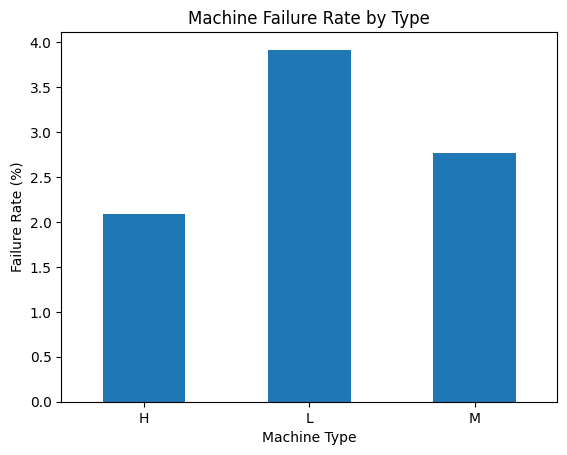

In [ ]:
failure_rate_by_type[1].plot(kind="bar")

plt.title("Machine Failure Rate by Type")
plt.xlabel("Machine Type")
plt.ylabel("Failure Rate (%)")
plt.xticks(rotation=0)
plt.show()

**4.4 Numerical Feature Statistics**

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


**4.5 Numerical Feature Distribution**

In [ ]:
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


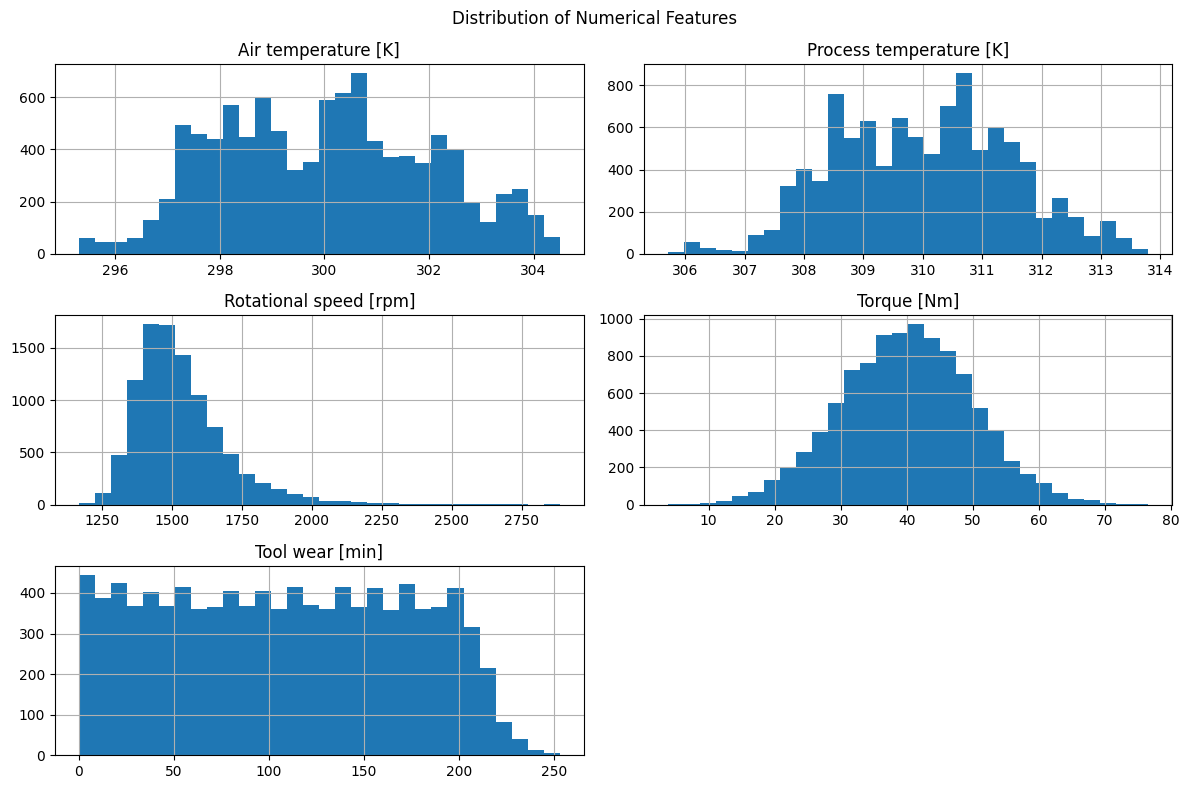

In [ ]:
df[numerical_features].hist(
    figsize=(12, 8),
    bins=30
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

**4.6 Outlier Analysis and Treatments**

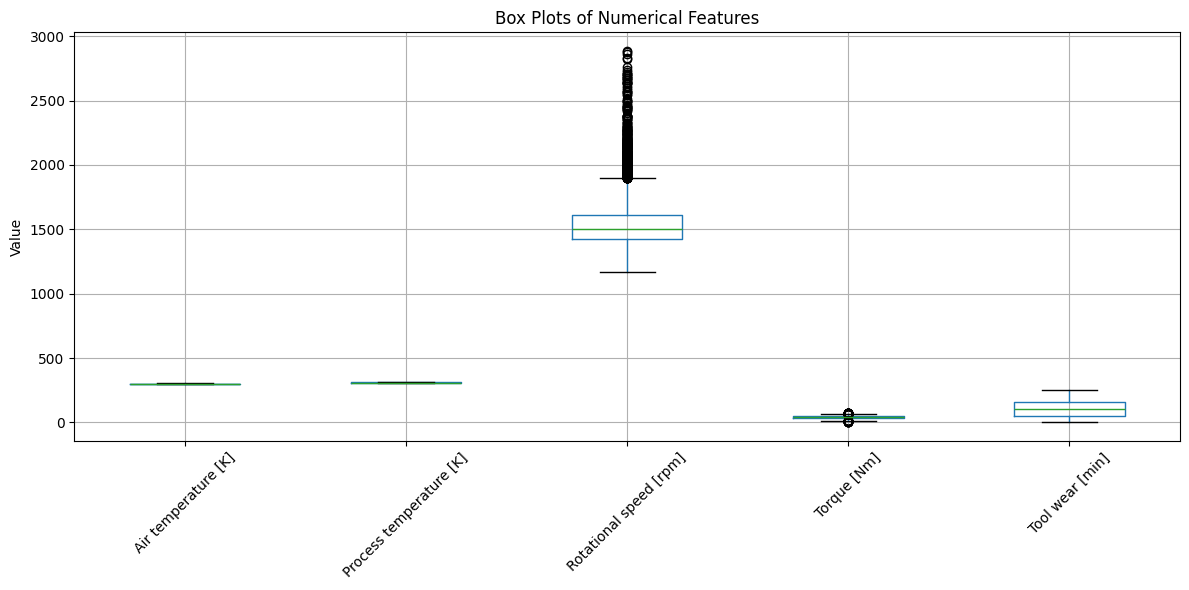

In [ ]:
plt.figure(figsize=(12, 6))

df[numerical_features].boxplot()

plt.title("Box Plots of Numerical Features")
plt.xticks(rotation=45)
plt.ylabel("Value")
plt.tight_layout()
plt.show()

In [ ]:

# Outlier Treatment Using IQR (Capping)

for col in numerical_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[col] = df[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Outlier treatment completed.")


Outlier treatment completed.


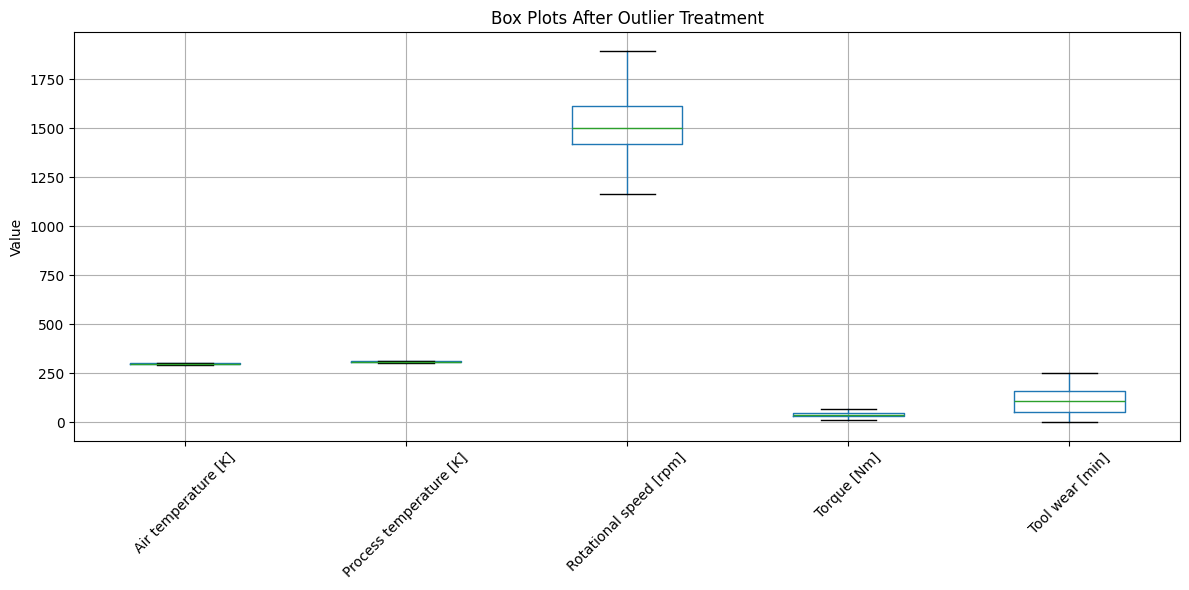

In [ ]:

plt.figure(figsize=(12, 6))

df[numerical_features].boxplot()

plt.title("Box Plots After Outlier Treatment")
plt.xticks(rotation=45)
plt.ylabel("Value")
plt.tight_layout()
plt.show()


**4.7 Numerical Features vs Failure**

<Figure size 700x500 with 0 Axes>

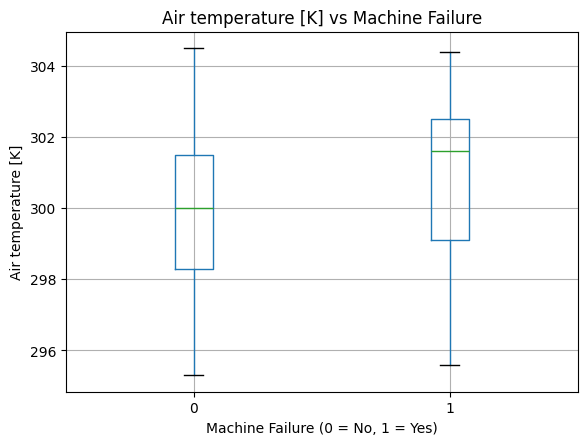

<Figure size 700x500 with 0 Axes>

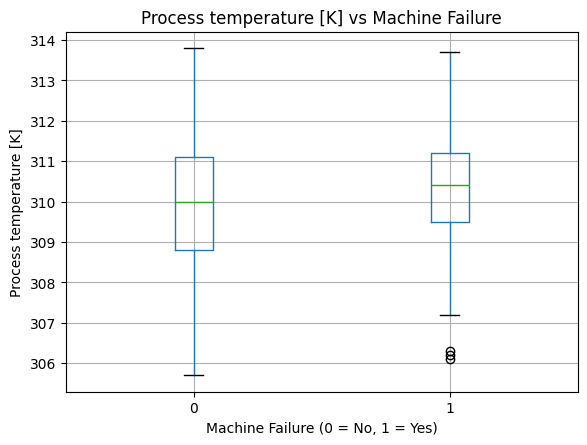

<Figure size 700x500 with 0 Axes>

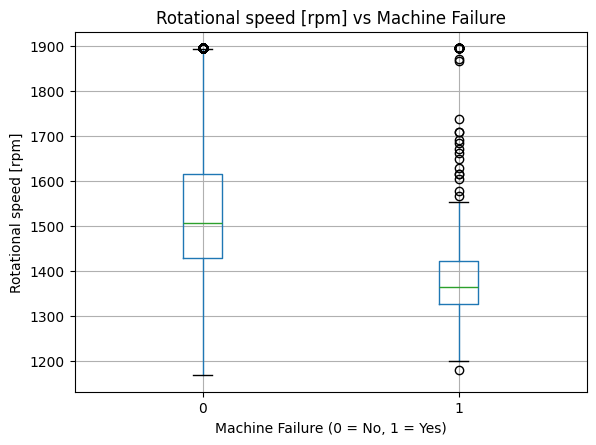

<Figure size 700x500 with 0 Axes>

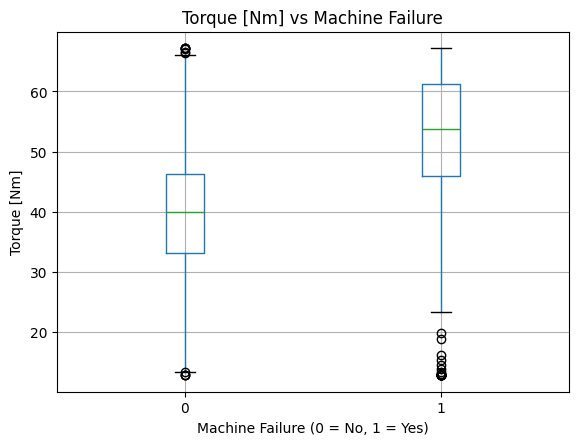

<Figure size 700x500 with 0 Axes>

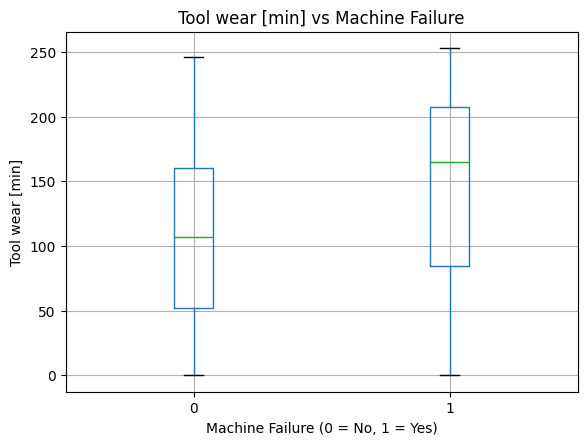

In [ ]:
for feature in numerical_features:
    plt.figure(figsize=(7, 5))

    df.boxplot(
        column=feature,
        by="Machine failure"
    )

    plt.title(f"{feature} vs Machine Failure")
    plt.suptitle("")
    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
    plt.ylabel(feature)

    plt.show()

In [ ]:
df.groupby("Machine failure")[numerical_features].mean().T

Machine failure,0,1
Air temperature [K],299.973999,300.886431
Process temperature [K],309.995570,310.290265
Rotational speed [rpm],1533.778853,1426.511799
Torque [Nm],39.629138,50.082006
Tool wear [min],106.693717,143.781711


**4.8 Correlation Analysis**

In [ ]:
correlation_matrix = df[numerical_features + ["Machine failure"]].corr()

correlation_matrix

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000000,0.876107,0.021305,-0.013861,0.013853,0.082556
Process temperature [K],0.876107,1.000000,0.019892,-0.014294,0.013488,0.035946
Rotational speed [rpm],0.021305,0.019892,1.000000,-0.911734,0.002496,-0.130467
Torque [Nm],-0.013861,-0.014294,-0.911734,1.000000,-0.003151,0.190806
Tool wear [min],0.013853,0.013488,0.002496,-0.003151,1.000000,0.105448
Machine failure,0.082556,0.035946,-0.130467,0.190806,0.105448,1.000000


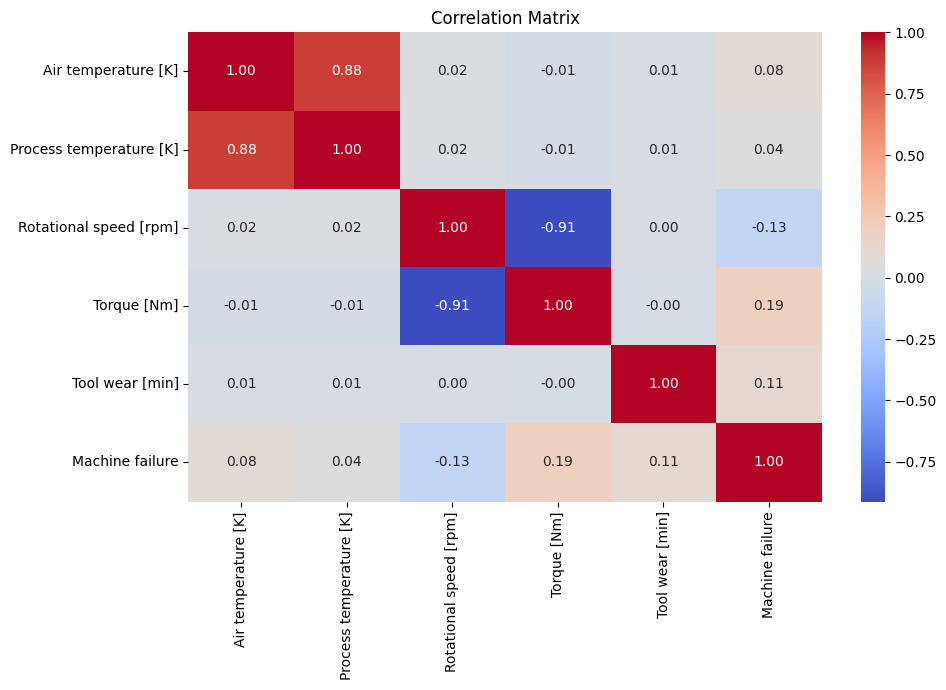

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

**4.9 Failure Mode Analysis**

In [ ]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

df[failure_modes].sum()

,0
TWF,46
HDF,115
PWF,95
OSF,98
RNF,19


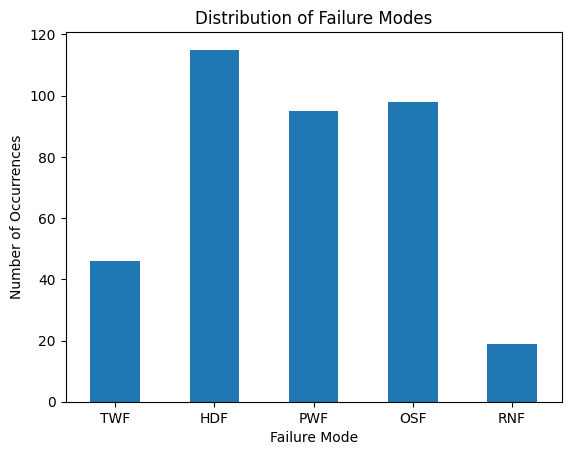

In [ ]:
df[failure_modes].sum().plot(kind="bar")

plt.title("Distribution of Failure Modes")
plt.xlabel("Failure Mode")
plt.ylabel("Number of Occurrences")
plt.xticks(rotation=0)
plt.show()

In [ ]:
pd.crosstab(
    df["Machine failure"],
    df[failure_modes].sum(axis=1)
)

col_0,0,1,2,3
Machine failure,,,,
0,9643,18,0,0
1,9,306,23,1


**5. Feature Selection**

**5.1 Identifier Variables**

In [ ]:
df["UDI"].nunique()

10000

In [ ]:
df["Product ID"].nunique()

10000

In [ ]:
df[["UDI", "Product ID"]].head()

,UDI,Product ID
0,1,M14860
1,2,L47181
2,3,L47182
3,4,L47183
4,5,L47184


**5.2 Predictive Variables**

In [ ]:
model_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

**5.3 Target Variable**

In [ ]:
target = "Machine failure"

**6. Data Preparation**

**6.1 Encoding**

In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder


encoder = OneHotEncoder(sparse_output=False)

encoded = encoder.fit_transform(df[['Type']])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(['Type'])
)

print(encoded_df.head())

   Type_H  Type_L  Type_M
0     0.0     0.0     1.0
1     0.0     1.0     0.0
2     0.0     1.0     0.0
3     0.0     1.0     0.0
4     0.0     1.0     0.0


In [ ]:
# Add encoded columns
df = pd.concat([df, encoded_df], axis=1)
# Remove original categorical column
df = df.drop('Type', axis=1)

In [ ]:
print(df.dtypes)

UDI                          int64
Product ID                  object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]     float64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
Type_H                     float64
Type_L                     float64
Type_M                     float64
dtype: object


**6.2 X and y**

In [ ]:
model_features = [
    "Type_H",
    "Type_L",
    "Type_M",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [ ]:
target = "Machine failure"

In [ ]:
X = df[model_features].copy()
y = df[target].copy()

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 8)
y shape: (10000,)


**6.2 Train/Test Split**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
X.head()

,Type_H,Type_L,Type_M,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,0.0,0.0,1.0,298.1,308.6,1551.0,42.8,0
1,0.0,1.0,0.0,298.2,308.7,1408.0,46.3,3
2,0.0,1.0,0.0,298.1,308.5,1498.0,49.4,5
3,0.0,1.0,0.0,298.2,308.6,1433.0,39.5,7
4,0.0,1.0,0.0,298.2,308.7,1408.0,40.0,9


In [ ]:
y.head()

,Machine failure
0,0
1,0
2,0
3,0
4,0


In [ ]:
print(X.shape, X_train.shape, X_test.shape)

(10000, 8) (8000, 8) (2000, 8)


**6.4 Scaling**

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train_standardized = scaler.transform(X_train)
X_test_standardized = scaler.transform(X_test)

In [ ]:
print(X_train_standardized.std())

1.0


**7. Class imbalance**

In [ ]:
print(y_train.value_counts())

Machine failure
0    7729
1     271
Name: count, dtype: int64


In [ ]:
print(y_train.value_counts(normalize=True) * 100)

Machine failure
0    96.6125
1     3.3875
Name: proportion, dtype: float64


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_standardized,
    y_train
)

In [ ]:
print("Before balancing:")
print(y_train.value_counts())

print("\nAfter balancing:")
print(y_train_balanced.value_counts())

Before balancing:
Machine failure
0    7729
1     271
Name: count, dtype: int64

After balancing:
Machine failure
0    7729
1    7729
Name: count, dtype: int64


**8. ML Models**

**8.1 SVM**

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Create model
svm_model = SVC(
    kernel='rbf',
    random_state=42
)

# Train
svm_model.fit(X_train_balanced, y_train_balanced)

# Prediction
y_pred_svm = svm_model.predict(X_test_standardized)

# Evaluation
print("========== SVM ==========")

print("Accuracy :", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall   :", recall_score(y_test, y_pred_svm))
print("F1 Score :", f1_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

========== SVM ==========
Accuracy : 0.9205
Precision: 0.28837209302325584
Recall   : 0.9117647058823529
F1 Score : 0.4381625441696113

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.92      0.96      1932
           1       0.29      0.91      0.44        68

    accuracy                           0.92      2000
   macro avg       0.64      0.92      0.70      2000
weighted avg       0.97      0.92      0.94      2000

Confusion Matrix:
[[1779  153]
 [   6   62]]


KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Create model
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

# Train
knn_model.fit(X_train_balanced, y_train_balanced)

# Prediction
y_pred_knn = knn_model.predict(X_test_standardized)

# Evaluation
print("========== KNN ==========")

print("Accuracy :", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn))
print("Recall   :", recall_score(y_test, y_pred_knn))
print("F1 Score :", f1_score(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

========== KNN ==========
Accuracy : 0.92
Precision: 0.2676767676767677
Recall   : 0.7794117647058824
F1 Score : 0.39849624060150374

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.92      0.96      1932
           1       0.27      0.78      0.40        68

    accuracy                           0.92      2000
   macro avg       0.63      0.85      0.68      2000
weighted avg       0.97      0.92      0.94      2000

Confusion Matrix:
[[1787  145]
 [  15   53]]


Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Create model
dt_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Train
dt_model.fit(X_train_balanced, y_train_balanced)

# Prediction
y_pred_dt = dt_model.predict(X_test_standardized)

# Evaluation
print("========== DECISION TREE ==========")

print("Accuracy :", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall   :", recall_score(y_test, y_pred_dt))
print("F1 Score :", f1_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

========== DECISION TREE ==========
Accuracy : 0.9535
Precision: 0.4
Recall   : 0.7352941176470589
F1 Score : 0.5181347150259067

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.96      0.98      1932
           1       0.40      0.74      0.52        68

    accuracy                           0.95      2000
   macro avg       0.70      0.85      0.75      2000
weighted avg       0.97      0.95      0.96      2000

Confusion Matrix:
[[1857   75]
 [  18   50]]


Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train
rf_model.fit(X_train_balanced, y_train_balanced)

# Prediction
y_pred_rf = rf_model.predict(X_test_standardized)

# Evaluation
print("========== RANDOM FOREST ==========")

print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

========== RANDOM FOREST ==========
Accuracy : 0.9605
Precision: 0.45217391304347826
Recall   : 0.7647058823529411
F1 Score : 0.5683060109289617

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1932
           1       0.45      0.76      0.57        68

    accuracy                           0.96      2000
   macro avg       0.72      0.87      0.77      2000
weighted avg       0.97      0.96      0.97      2000

Confusion Matrix:
[[1869   63]
 [  16   52]]


XGBoost

In [ ]:

# Step 1B: XGBoost Model

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train_balanced, y_train_balanced)

y_pred_xgb = xgb_model.predict(X_test_standardized)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("XGBoost Precision:", precision_score(
    y_test, y_pred_xgb, zero_division=0
))
print("XGBoost Recall:", recall_score(
    y_test, y_pred_xgb, zero_division=0
))
print("XGBoost F1 Score:", f1_score(
    y_test, y_pred_xgb, zero_division=0
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))


XGBoost Accuracy: 0.9145
XGBoost Precision: 0.27312775330396477
XGBoost Recall: 0.9117647058823529
XGBoost F1 Score: 0.42033898305084744

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.91      0.95      1932
           1       0.27      0.91      0.42        68

    accuracy                           0.91      2000
   macro avg       0.63      0.91      0.69      2000
weighted avg       0.97      0.91      0.94      2000

Confusion Matrix:
[[1767  165]
 [   6   62]]


Comparison table

In [ ]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = pd.DataFrame({
    'Model': [
        'SVM',
        'KNN',
        'Decision Tree',
        'Random Forest',
        'XGBoost'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],

    'Precision': [
        precision_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],

    'Recall': [
        recall_score(y_test, y_pred_svm),
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ]
})

print(results)

           Model  Accuracy  Precision    Recall  F1 Score
0            SVM    0.9205   0.288372  0.911765  0.438163
1            KNN    0.9200   0.267677  0.779412  0.398496
2  Decision Tree    0.9535   0.400000  0.735294  0.518135
3  Random Forest    0.9605   0.452174  0.764706  0.568306
4        XGBoost    0.9145   0.273128  0.911765  0.420339


Confusion matrices

In [ ]:
print("SVM Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

print("\nKNN Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nDecision Tree Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nRandom Forest Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nXGBoost Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

SVM Confusion Matrix:
[[1779  153]
 [   6   62]]

KNN Confusion Matrix:
[[1787  145]
 [  15   53]]

Decision Tree Confusion Matrix:
[[1857   75]
 [  18   50]]

Random Forest Confusion Matrix:
[[1869   63]
 [  16   52]]

XGBoost Confusion Matrix:
[[1767  165]
 [   6   62]]


Feature Importance(just analysis)
1. Random Forest

                   Feature  Importance
6              Torque [Nm]    0.313563
5   Rotational speed [rpm]    0.277896
7          Tool wear [min]    0.195703
3      Air temperature [K]    0.111771
4  Process temperature [K]    0.078461
1                   Type_L    0.010164
2                   Type_M    0.007497
0                   Type_H    0.004945


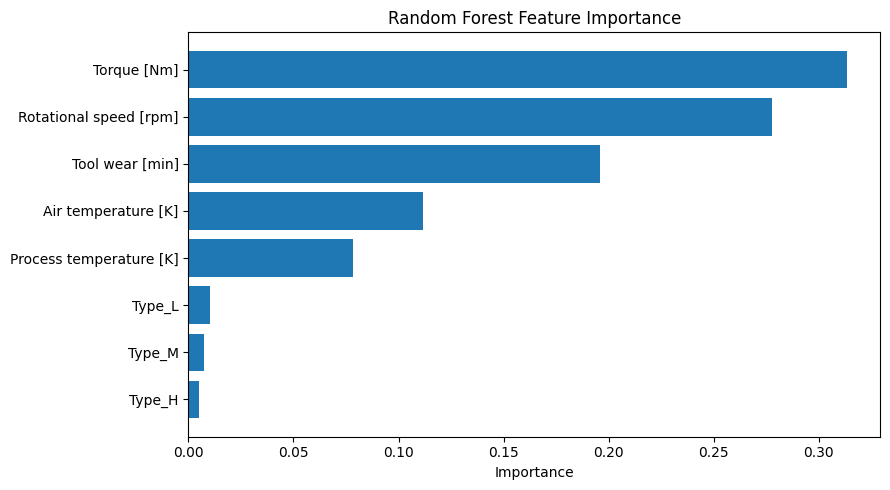

In [ ]:

# Step 1A: Random Forest Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print(rf_importance)

plt.figure(figsize=(9, 5))
plt.barh(rf_importance["Feature"], rf_importance["Importance"])
plt.xlabel("Importance")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


2. XGBoost

                   Feature  Importance
5   Rotational speed [rpm]    0.325131
7          Tool wear [min]    0.225233
6              Torque [Nm]    0.209446
3      Air temperature [K]    0.136399
4  Process temperature [K]    0.049582
2                   Type_M    0.021395
1                   Type_L    0.019160
0                   Type_H    0.013653


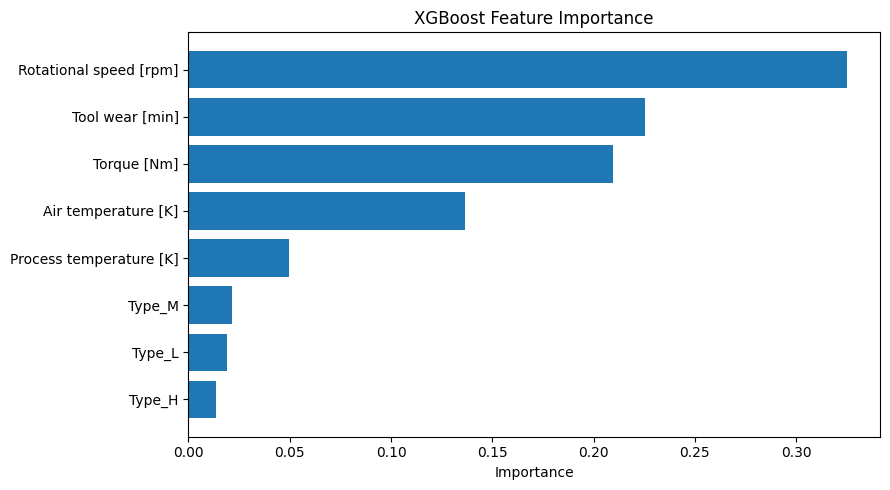

In [ ]:

# Step 1B: XGBoost Feature Importance

xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
}).sort_values("Importance", ascending=False)

print(xgb_importance)

plt.figure(figsize=(9, 5))
plt.barh(xgb_importance["Feature"], xgb_importance["Importance"])
plt.xlabel("Importance")
plt.title("XGBoost Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


**Hyperparameter Optimization**

1.Tune SVM

In [ ]:
# Define cross-validation

from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

svm_model = SVC(random_state=42)

svm_params = {
    "C": [0.1, 1, 10],
    "kernel": ["rbf", "linear"],
    "gamma": ["scale", "auto"]
}

svm_grid = GridSearchCV(
    estimator=svm_model,
    param_grid=svm_params,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

svm_grid.fit(X_train_balanced, y_train_balanced)

print("Best SVM parameters:", svm_grid.best_params_)
print("Best CV F1:", svm_grid.best_score_)

best_svm = svm_grid.best_estimator_
y_pred_svm = best_svm.predict(X_test_standardized)

print("\nSVM Classification Report:")
print(classification_report(y_test, y_pred_svm))

Best SVM parameters: {'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}
Best CV F1: 0.9585022553363732

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      1932
           1       0.32      0.84      0.46        68

    accuracy                           0.93      2000
   macro avg       0.66      0.89      0.71      2000
weighted avg       0.97      0.93      0.95      2000



In [ ]:
from sklearn.metrics import f1_score, accuracy_score

print("Test Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Test Failure F1:", f1_score(y_test, y_pred_svm))

Test Accuracy: 0.933
Test Failure F1: 0.4596774193548387


In [ ]:

# Step 2B: SVM Hyperparameter Tuning

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

svm_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", SVC(random_state=42))
])

svm_params = [
    {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear"]
    },
    {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["rbf"],
        "model__gamma": ["scale", "auto"]
    }
]

svm_grid = GridSearchCV(
    svm_pipe,
    svm_params,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

print("Best SVM parameters:", svm_grid.best_params_)
print("Best CV F1:", svm_grid.best_score_)

y_pred_svm = svm_grid.predict(X_test)

from sklearn.metrics import classification_report, accuracy_score, f1_score

print("Test Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Test Failure F1:", f1_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))


Best SVM parameters: {'model__C': 10, 'model__gamma': 'auto', 'model__kernel': 'rbf'}
Best CV F1: 0.4668327748075004
Test Accuracy: 0.933
Test Failure F1: 0.4596774193548387
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      1932
           1       0.32      0.84      0.46        68

    accuracy                           0.93      2000
   macro avg       0.66      0.89      0.71      2000
weighted avg       0.97      0.93      0.95      2000



Tune KNN

In [ ]:

# Step 3A: KNN Hyperparameter Tuning

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, accuracy_score, f1_score

knn_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", KNeighborsClassifier())
])

knn_params = {
    "model__n_neighbors": [3, 5, 7, 9],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

knn_grid = GridSearchCV(
    knn_pipe,
    knn_params,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

print("Best KNN parameters:", knn_grid.best_params_)
print("Best CV F1:", knn_grid.best_score_)

y_pred_knn = knn_grid.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Test Failure F1:", f1_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

Best KNN parameters: {'model__n_neighbors': 3, 'model__p': 2, 'model__weights': 'distance'}
Best CV F1: 0.4284376622719396
Test Accuracy: 0.934
Test Failure F1: 0.4406779661016949
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      1932
           1       0.31      0.76      0.44        68

    accuracy                           0.93      2000
   macro avg       0.65      0.85      0.70      2000
weighted avg       0.97      0.93      0.95      2000



Tune Decision Tree

In [ ]:

# Step 3B: Decision Tree Hyperparameter Tuning

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, accuracy_score, f1_score

dt_pipe = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", DecisionTreeClassifier(random_state=42))
])

dt_params = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [5, 10, 15, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

dt_grid = GridSearchCV(
    dt_pipe,
    dt_params,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best Decision Tree parameters:", dt_grid.best_params_)
print("Best CV F1:", dt_grid.best_score_)

y_pred_dt = dt_grid.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Test Failure F1:", f1_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Best Decision Tree parameters: {'model__criterion': 'entropy', 'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2}
Best CV F1: 0.5480239623196226
Test Accuracy: 0.9625
Test Failure F1: 0.576271186440678
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1932
           1       0.47      0.75      0.58        68

    accuracy                           0.96      2000
   macro avg       0.73      0.86      0.78      2000
weighted avg       0.97      0.96      0.97      2000



Tune Random Forest

In [ ]:

# Step 3C: Random Forest Hyperparameter Tuning

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, accuracy_score, f1_score

rf_pipe = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(random_state=42, n_jobs=1))
])

rf_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", "log2"]
}

rf_grid = GridSearchCV(
    rf_pipe,
    rf_params,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:", rf_grid.best_params_)
print("Best CV F1:", rf_grid.best_score_)

y_pred_rf = rf_grid.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Test Failure F1:", f1_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Best Random Forest parameters: {'model__max_depth': None, 'model__max_features': 'log2', 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
Best CV F1: 0.5785846420603773
Test Accuracy: 0.964
Test Failure F1: 0.5714285714285714
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1932
           1       0.48      0.71      0.57        68

    accuracy                           0.96      2000
   macro avg       0.73      0.84      0.78      2000
weighted avg       0.97      0.96      0.97      2000



Tune XGBoost

In [ ]:
print("X_train shape:", X_train.shape)
print("X_train data types:")
print(X_train.dtypes)

print("\ny_train classes:")
print(y_train.value_counts())

X_train shape: (8000, 8)
X_train data types:
Type_H                     float64
Type_L                     float64
Type_M                     float64
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]     float64
Torque [Nm]                float64
Tool wear [min]              int64
dtype: object

y_train classes:
Machine failure
0    7729
1     271
Name: count, dtype: int64


In [ ]:
# Make feature names compatible with XGBoost

X_train.columns = [
    "Type_H",
    "Type_L",
    "Type_M",
    "Air_temperature_K",
    "Process_temperature_K",
    "Rotational_speed_rpm",
    "Torque_Nm",
    "Tool_wear_min"
]

X_test.columns = [
    "Type_H",
    "Type_L",
    "Type_M",
    "Air_temperature_K",
    "Process_temperature_K",
    "Rotational_speed_rpm",
    "Torque_Nm",
    "Tool_wear_min"
]

In [ ]:

# XGBoost Hyperparameter Tuning

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

xgb_pipe = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=1
    ))
])

xgb_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.01, 0.1],
    "model__subsample": [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=xgb_pipe,
    param_grid=xgb_params,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

print("Best XGBoost parameters:", xgb_grid.best_params_)
print("Best CV F1:", xgb_grid.best_score_)

y_pred_xgb = xgb_grid.predict(X_test)

print("\nTest Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Test Precision:", precision_score(y_test, y_pred_xgb, zero_division=0))
print("Test Recall:", recall_score(y_test, y_pred_xgb, zero_division=0))
print("Test Failure F1:", f1_score(y_test, y_pred_xgb, zero_division=0))

print("\nXGBoost Classification Report:")
print(classification_report(y_test, y_pred_xgb))


Best XGBoost parameters: {'model__learning_rate': 0.1, 'model__max_depth': 7, 'model__n_estimators': 200, 'model__subsample': 1.0}
Best CV F1: 0.6412657228189111

Test Accuracy: 0.974
Test Precision: 0.5930232558139535
Test Recall: 0.75
Test Failure F1: 0.6623376623376623

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1932
           1       0.59      0.75      0.66        68

    accuracy                           0.97      2000
   macro avg       0.79      0.87      0.82      2000
weighted avg       0.98      0.97      0.98      2000



In [ ]:

# Step 4: Compare Tuned Models

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "SVM": (svm_grid, y_pred_svm),
    "KNN": (knn_grid, y_pred_knn),
    "Decision Tree": (dt_grid, y_pred_dt),
    "Random Forest": (rf_grid, y_pred_rf),
    "XGBoost": (xgb_grid, y_pred_xgb)
}

results = []

for name, (grid, pred) in models.items():
    results.append({
        "Model": name,
        "Best CV F1": grid.best_score_,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

           Model  Best CV F1  Accuracy  Precision  Recall  F1 Score
0            SVM      0.4668    0.9330     0.3167  0.8382    0.4597
1            KNN      0.4284    0.9340     0.3095  0.7647    0.4407
2  Decision Tree      0.5480    0.9625     0.4679  0.7500    0.5763
3  Random Forest      0.5786    0.9640     0.4800  0.7059    0.5714
4        XGBoost      0.6413    0.9740     0.5930  0.7500    0.6623


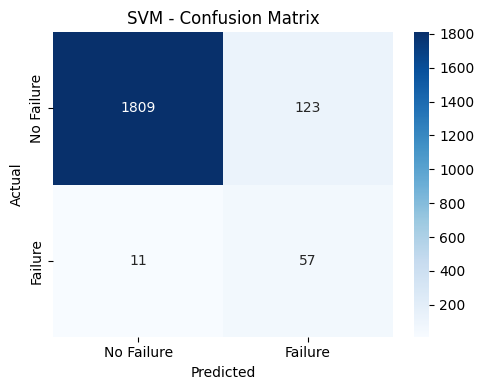

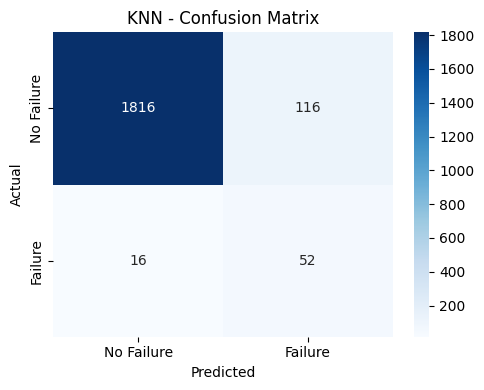

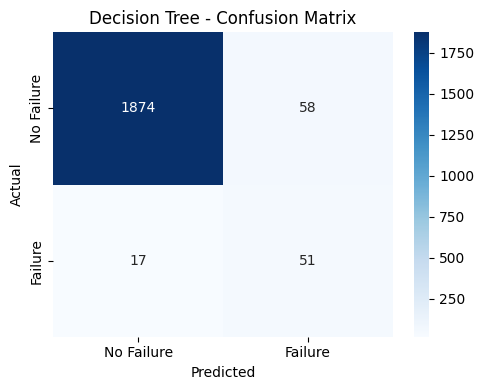

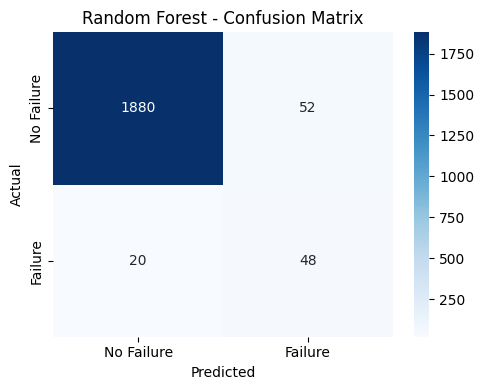

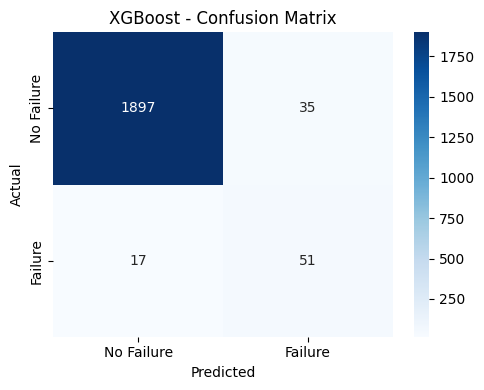

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

predictions = {
    "SVM": y_pred_svm,
    "KNN": y_pred_knn,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Failure", "Failure"],
        yticklabels=["No Failure", "Failure"]
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()


In [ ]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

models = {
    "SVM": (svm_grid, y_pred_svm),
    "KNN": (knn_grid, y_pred_knn),
    "Decision Tree": (dt_grid, y_pred_dt),
    "Random Forest": (rf_grid, y_pred_rf),
    "XGBoost": (xgb_grid, y_pred_xgb)
}

results = []

for name, (grid, pred) in models.items():
    results.append({
        "Model": name,
        "Best CV F1": grid.best_score_,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("F1 Score", ascending=False)

print(results_df.round(4).to_string(index=False))

print("\nSelected candidate: XGBoost")
print("Best parameters:")
print(xgb_grid.best_params_)


        Model  Best CV F1  Accuracy  Precision  Recall  F1 Score
      XGBoost      0.6413    0.9740     0.5930  0.7500    0.6623
Decision Tree      0.5480    0.9625     0.4679  0.7500    0.5763
Random Forest      0.5786    0.9640     0.4800  0.7059    0.5714
          SVM      0.4668    0.9330     0.3167  0.8382    0.4597
          KNN      0.4284    0.9340     0.3095  0.7647    0.4407

Selected candidate: XGBoost
Best parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 7, 'model__n_estimators': 200, 'model__subsample': 1.0}


SHAP

In [ ]:

import shap
import matplotlib.pyplot as plt
import pandas as pd

# Extract the trained XGBoost estimator from the pipeline
xgb_model = xgb_grid.best_estimator_.named_steps["model"]

# Use original, unresampled test data
X_shap = X_test.copy()

# Explain predictions using Tree SHAP
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_shap)

print("SHAP analysis completed.")
print("Test samples:", X_shap.shape[0])
print("Features:", list(X_shap.columns))


SHAP analysis completed.
Test samples: 2000
Features: ['Type_H', 'Type_L', 'Type_M', 'Air_temperature_K', 'Process_temperature_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min']


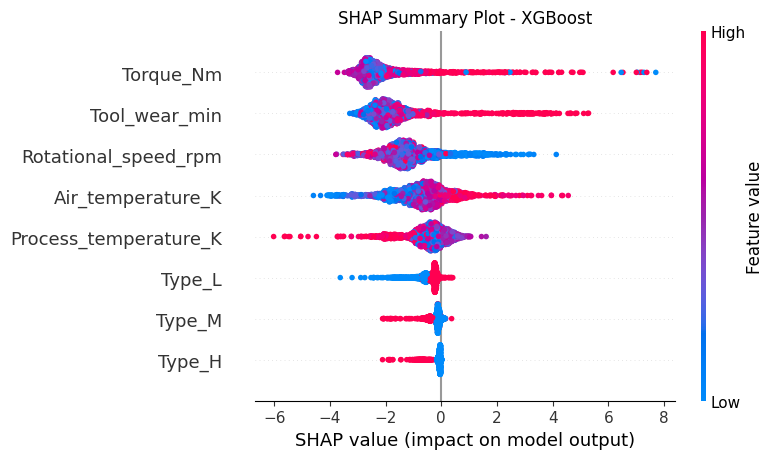

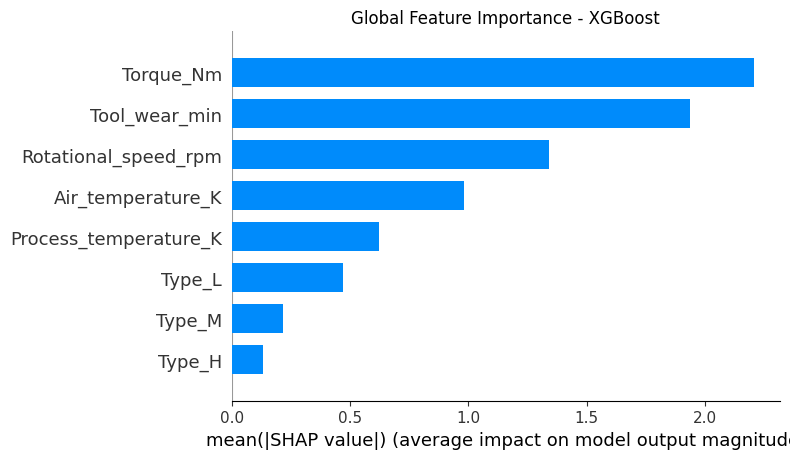

In [ ]:

# Summary plot: feature importance and direction of influence
shap.summary_plot(
    shap_values,
    X_shap,
    show=False
)
plt.title("SHAP Summary Plot - XGBoost")
plt.tight_layout()
plt.show()

# Bar plot: mean absolute SHAP importance
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    show=False
)
plt.title("Global Feature Importance - XGBoost")
plt.tight_layout()
plt.show()


Test observation index: 21
Actual outcome: 1
Predicted outcome: 1


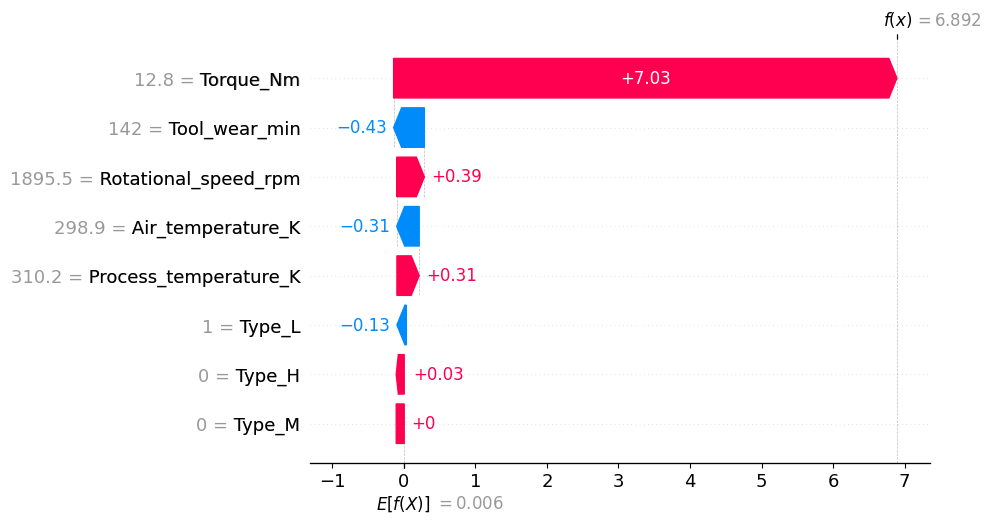

In [ ]:

import numpy as np

# Find test observations predicted as failures
failure_indices = np.where(np.asarray(y_pred_xgb) == 1)[0]

if len(failure_indices) > 0:
    i = int(failure_indices[0])

    print("Test observation index:", i)
    print("Actual outcome:", y_test.iloc[i] if hasattr(y_test, "iloc") else y_test[i])
    print("Predicted outcome:", np.asarray(y_pred_xgb)[i])

    # SHAP waterfall explanation
    explanation = shap.Explanation(
        values=shap_values[i],
        base_values=explainer.expected_value,
        data=X_shap.iloc[i].values,
        feature_names=X_shap.columns.tolist()
    )

    shap.plots.waterfall(explanation)
else:
    print("No failures were predicted in the test set.")


Failure Analysis

['UDI', 'Product ID', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF', 'Type_H', 'Type_L', 'Type_M']
  Machine Type  Total Machines  Failure Count  Failure Rate  Failure Rate (%)
0            H            1003             21          0.02              2.09
1            L            6000            235          0.04              3.92
2            M            2997             83          0.03              2.77


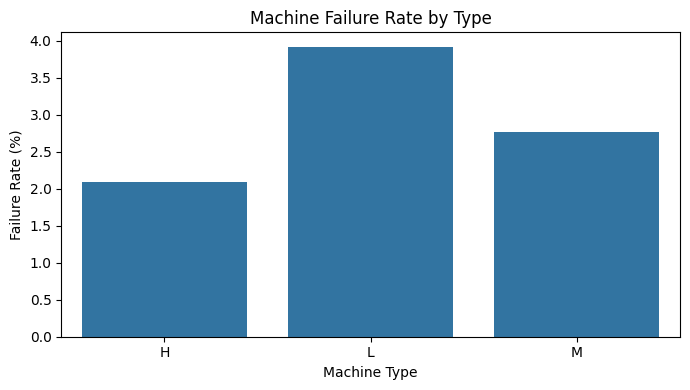

In [ ]:


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Identify machine type from one-hot encoded columns
type_columns = ["Type_H", "Type_L", "Type_M"]

print(df.columns.tolist())

if all(col in df.columns for col in type_columns):
    df["Machine Type"] = df[type_columns].idxmax(axis=1).str.replace(
        "Type_", "", regex=False
    )
elif "Type" in df.columns:
    df["Machine Type"] = df["Type"]
else:
    raise ValueError(
        "Machine type columns are missing. Check df.columns.tolist() "
        "and use your original AI4I dataset for this analysis."
    )

# Calculate failure counts and rates by type
failure_by_type = (
    df.groupby("Machine Type")["Machine failure"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

failure_by_type.columns = [
    "Machine Type", "Total Machines", "Failure Count", "Failure Rate"
]

failure_by_type["Failure Rate (%)"] = (
    failure_by_type["Failure Rate"] * 100
)

print(failure_by_type.round(2))

# Plot failure rates
plt.figure(figsize=(7, 4))
sns.barplot(
    data=failure_by_type,
    x="Machine Type",
    y="Failure Rate (%)"
)
plt.title("Machine Failure Rate by Type")
plt.xlabel("Machine Type")
plt.ylabel("Failure Rate (%)")
plt.tight_layout()
plt.show()


Feature statistics by actual failure status:
                Air temperature [K]              Process temperature [K]  \
                               mean median   std                    mean   
Machine failure                                                            
0                            299.97  300.0  1.99                  310.00   
1                            300.89  301.6  2.07                  310.29   

                             Rotational speed [rpm]                  \
                median   std                   mean  median     std   
Machine failure                                                       
0                310.0  1.49                1533.78  1507.0  146.11   
1                310.4  1.36                1426.51  1365.0  183.67   

                Torque [Nm]               Tool wear [min]                
                       mean median    std            mean median    std  
Machine failure                                                       

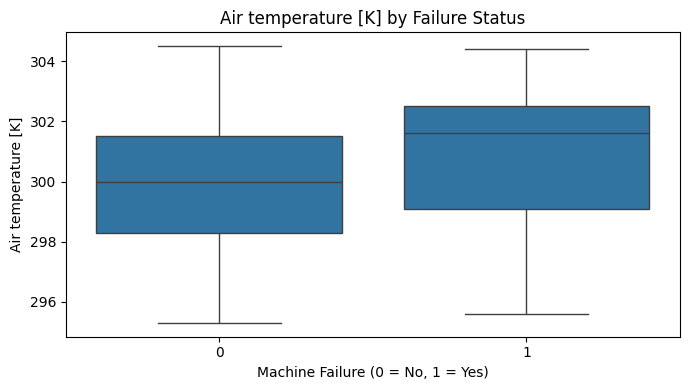

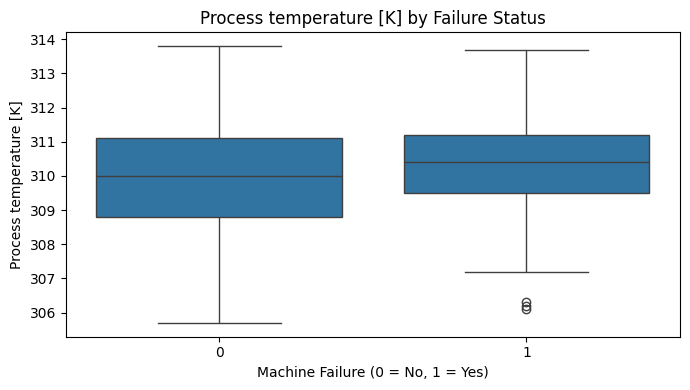

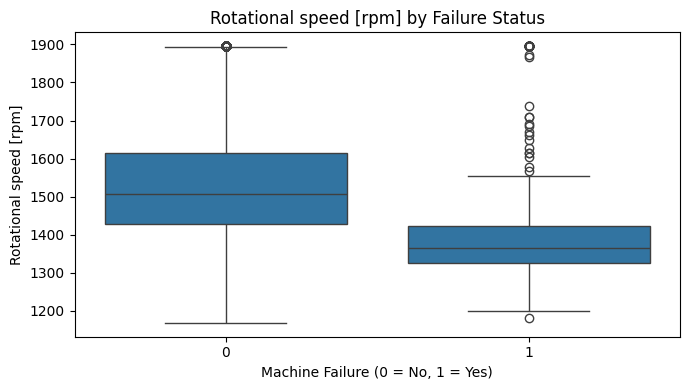

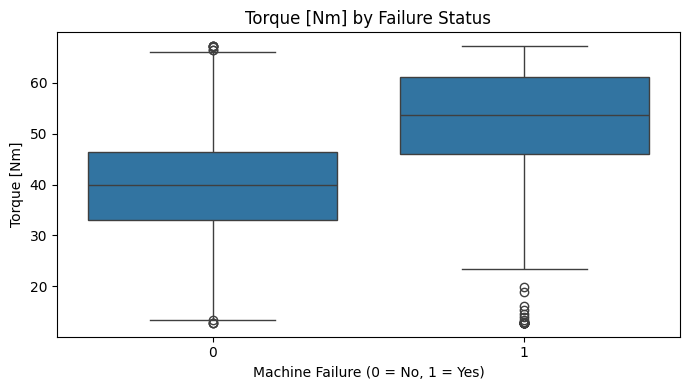

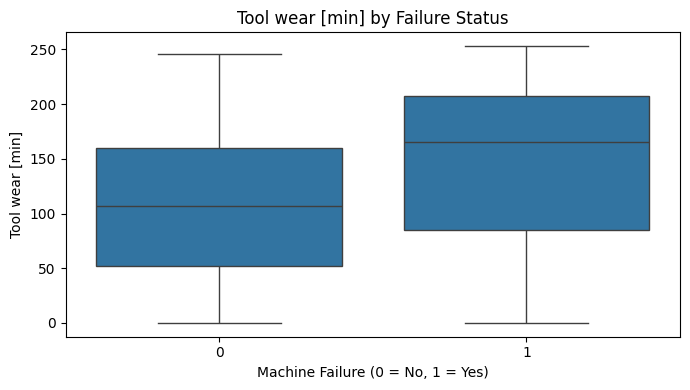

In [ ]:

features_to_analyze = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

print("Feature statistics by actual failure status:")

print(
    df.groupby("Machine failure")[features_to_analyze]
      .agg(["mean", "median", "std"])
      .round(2)
)

for feature in features_to_analyze:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature
    )

    plt.title(f"{feature} by Failure Status")
    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
    plt.tight_layout()
    plt.show()


Recorded failure-mode counts:
HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64


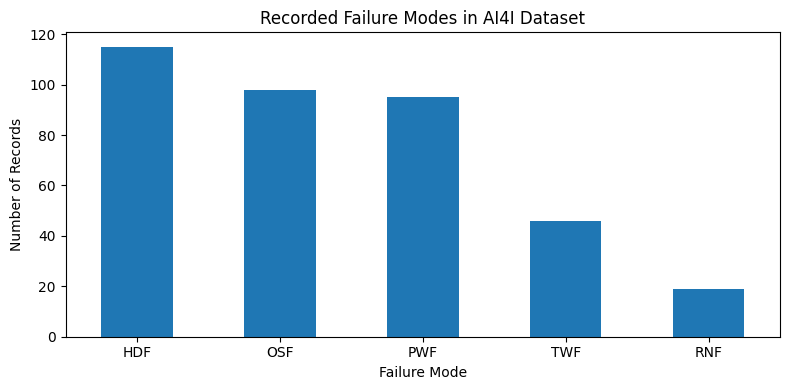

In [ ]:

failure_mode_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

mode_counts = df[failure_mode_columns].sum().sort_values(
    ascending=False
)

print("Recorded failure-mode counts:")
print(mode_counts)

plt.figure(figsize=(8, 4))
mode_counts.plot(kind="bar")
plt.title("Recorded Failure Modes in AI4I Dataset")
plt.xlabel("Failure Mode")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

# Save the comparison table
results_df.to_csv("model_comparison.csv", index=False)


print("Saved model comparison results.")


Saved model comparison results.
